# Time-to-Positivity and Mortality in Bacteremia

Updated Bayesian Meta-Analysis (v4 database)

In [ ]:
#| include: false
suppressPackageStartupMessages({
  library(tidyverse)
  library(brms)
  library(metafor)
  library(posterior)
  library(bayesplot)
  library(ggdist)
  library(patchwork)
  library(knitr)
  library(gt)
})

Pool: 100 studies (inclusive_pool=FALSE, drop_contaminated=TRUE)

Pool: 140 studies (inclusive_pool=TRUE, drop_contaminated=TRUE)

In [ ]:
#| include: false
#| cache: false
# Summaries are always recomputed from the cached fits so changes to
# pooled_summary() (e.g. adding pi_OR) take effect without clearing the cache.
source("R/02_fit_models.R")
base_post <- pooled_summary(fits$fit_base)
inc_post  <- pooled_summary(fits_inc$fit_base)

# Executive summary

``` r
#| results: asis
n_studies   <- attr(es_all, "n_studies")
n_es        <- nrow(es_mort)
n_studies_i <- attr(es_all_inc, "n_studies")
n_es_i      <- nrow(es_mort_inc)
cat(sprintf("**Primary analysis** (strict pool): %d studies contributing %d mortality effect sizes.  \n", n_studies, n_es))
```

**Primary analysis** (strict pool): 100 studies contributing 72 mortality effect sizes.

``` r
#| results: asis
cat(sprintf("**Sensitivity analysis** (strict + inclusive pool): %d studies, %d effect sizes.  \n", n_studies_i, n_es_i))
```

**Sensitivity analysis** (strict + inclusive pool): 140 studies, 84 effect sizes.

> **Primary result (strict pool)**
>
> **Pooled odds ratio for mortality (short vs long TTP):**
>
> ``` r
> #| results: asis
> cat(sprintf("- **OR = %.2f** (95%% CrI: %.2f–%.2f)  \n",
>             base_post$median_OR, base_post$ci_OR[1], base_post$ci_OR[2]))
> ```
>
> - **OR = 2.06** (95% CrI: 1.67–2.55)
>
> ``` r
> #| results: asis
> cat(sprintf("- 95%% prediction interval (new study): **%.2f–%.2f**  \n",
>             base_post$pi_OR[1], base_post$pi_OR[2]))
> ```
>
> - 95% prediction interval (new study): **0.50–8.41**
>
> ``` r
> #| results: asis
> cat(sprintf("- Probability that shorter TTP increases mortality: **%.1f%%**  \n", base_post$p_harm * 100))
> ```
>
> - Probability that shorter TTP increases mortality: **100.0%**
>
> ``` r
> #| results: asis
> cat(sprintf("- Between-study heterogeneity: I² = %.0f%%, τ = %.2f  \n", base_post$median_i2, base_post$median_tau))
> ```
>
> - Between-study heterogeneity: I² = 62%, τ = 0.69  

> **Sensitivity result (n=140)**
>
> ``` r
> #| results: asis
> cat(sprintf("Including the 40 inclusive-pool studies: **OR = %.2f** (95%% CrI: %.2f–%.2f), P(harm) = %.1f%%, I² = %.0f%%.  \n",
>             inc_post$median_OR, inc_post$ci_OR[1], inc_post$ci_OR[2],
>             inc_post$p_harm * 100, inc_post$median_i2))
> ```
>
> Including the 40 inclusive-pool studies: **OR = 1.92** (95% CrI: 1.58–2.35), P(harm) = 100.0%, I² = 63%.

# Background

Bloodstream infections are associated with significant morbidity and mortality. Time-to-positivity (TTP) — the interval between blood culture incubation start and detection of bacterial growth — has been proposed as a prognostic marker. Faster growth (shorter TTP) reflects higher bacterial burden or pathogen virulence, hypothesised to predict worse clinical outcomes.

This is the v4 update of a previously-published meta-analysis that included 57 studies (Feb 2026). The database has been expanded with 43 newly-extracted studies meeting the original strict eligibility criterion (quantitative TTP↔outcome association), yielding the n=100 primary pool. An additional 40 studies meeting an inclusive criterion (TTP + outcome both reported in the cohort, even without a formal model) form the n=140 sensitivity pool.

# Methods

## Data source

The analysis dataset is `data/TTP_MetaAnalysis_Extraction_Complete_v4.xlsx`. Effect sizes (log odds ratios) were computed using `metafor::escalc()`:

- **2×2 tables** when events/totals by TTP category are reported (preferred when available)
- **Back-calculated** from reported OR/HR/RR with 95% CI when 2×2 unavailable
- **Per-hour estimates** (continuous TTP) reported separately

The full effect-size pipeline is in `R/01_prepare_data.R`.

## Bayesian random-effects meta-analysis

Primary model (specified in `R/02_fit_models.R`):

$$y_i \mid \text{SE}_i \sim \mathcal{N}\!\left(\mu + u_s,\,\text{SE}_i^2\right),\quad u_s \sim \mathcal{N}(0,\tau^2)$$

with weakly-informative priors $\mu \sim \mathcal{N}(0,1)$, $\tau \sim \text{Half-Cauchy}(0,0.5)$, moderator coefficients $\mathcal{N}(0,0.5)$. Fitted with `brms` 4×4000 iterations (1000 warm-up), `adapt_delta = 0.99`, `max_treedepth = 12`.

## PRISMA flow

{#fig-prisma width="100%"}

# Primary results — mortality

## Overall pooled effect

In [ ]:
#| label: tbl-overall
#| tbl-cap: "Pooled effect of short vs long TTP on mortality (OR > 1 = short TTP harmful). Primary pool only (strict criterion)."
tibble(
  Parameter = c("Median OR (short vs long TTP)",
                "95% credible interval",
                "95% prediction interval (new study)",
                "P(short TTP harmful)",
                "Between-study SD (τ)",
                "Heterogeneity (I²)"),
  Value = c(
    sprintf("%.2f", base_post$median_OR),
    sprintf("[%.2f, %.2f]", base_post$ci_OR[1], base_post$ci_OR[2]),
    sprintf("[%.2f, %.2f]", base_post$pi_OR[1], base_post$pi_OR[2]),
    sprintf("%.1f%%", base_post$p_harm * 100),
    sprintf("%.2f", base_post$median_tau),
    sprintf("%.0f%%", base_post$median_i2)
  )
) |> gt() |>
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_body(rows = 1)) |>
  tab_style(style = cell_text(style = "italic", color = "gray40"),
            locations = cells_body(rows = 3))

## Forest plot

Warning in set2(resolve(...)): The object is read-only and cannot be modified.
If you have to modify it for a legitimate reason, call the method $lock(FALSE)
on the object before $set(). Using $lock(FALSE) to modify the object will be
enforced in future versions of knitr and this warning will become an error.

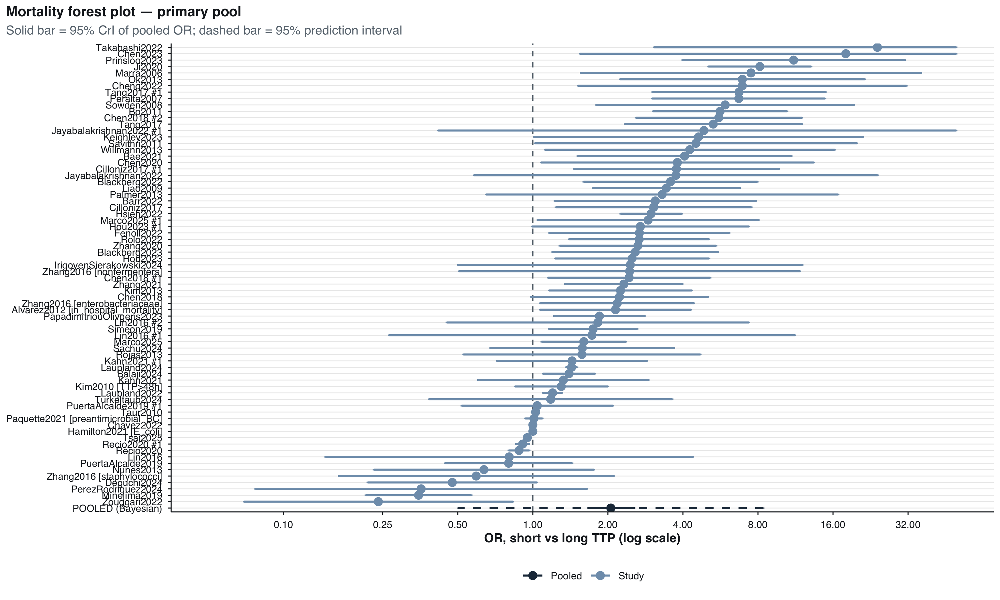

In [ ]:
#| label: fig-forest
#| fig-cap: "Forest plot of OR (short vs long TTP) on mortality — primary pool. Each row is a single effect size; multi-arm studies appear multiple times. Pooled estimate from the Bayesian model in dark navy."

fig_h <- max(6, nrow(es_mort) * 0.55 + 2)
knitr::opts_current$set(fig.height = fig_h)

## Posterior density of pooled OR

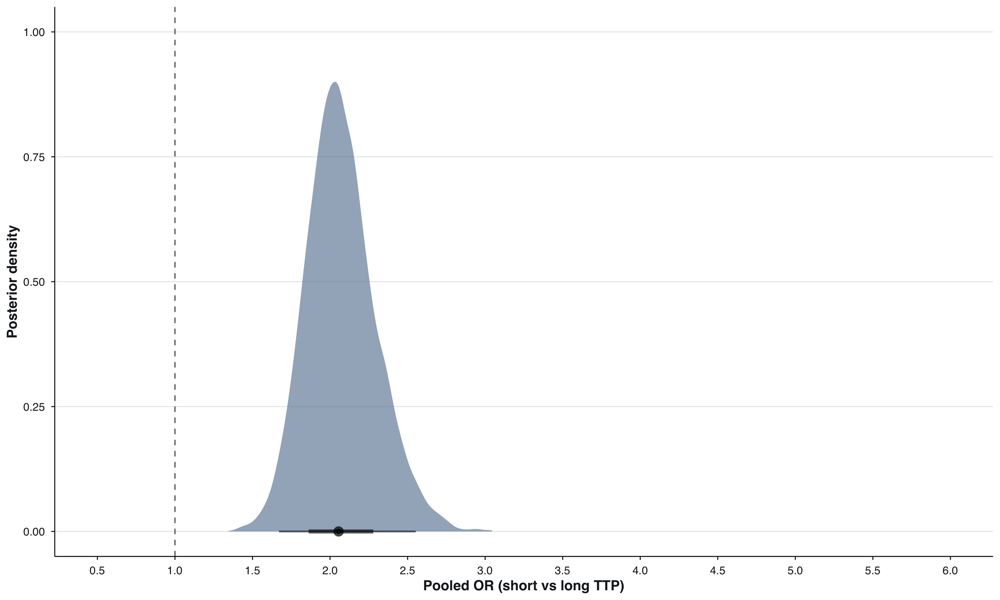

In [ ]:
#| label: fig-posterior
#| fig-cap: "Posterior density of the pooled OR (short vs long TTP). The vertical dashed line marks no effect (OR = 1)."
post_df <- tibble(OR = base_post$OR_draws)
ggplot(post_df, aes(x = OR)) +
  stat_halfeye(fill = "#5B7A99", alpha = 0.6) +
  geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
  scale_x_continuous(limits = c(0.5, 6), breaks = seq(0.5, 6, 0.5)) +
  labs(x = "Pooled OR (short vs long TTP)", y = "Posterior density") +
  theme_jama()

## Diagnostics

In [ ]:
#| label: tbl-diag
#| tbl-cap: "Convergence diagnostics for the primary pooled model."
posterior::summarise_draws(
  as_draws_df(fits$fit_base),
  rhat = posterior::rhat,
  ess_bulk = posterior::ess_bulk
) |>
  filter(!grepl("^lp__|^lprior", variable)) |>
  transmute(
    Parameter = variable,
    `R̂` = sprintf("%.3f", rhat),
    ESS_bulk = sprintf("%.0f", ess_bulk)
  ) |>
  gt()

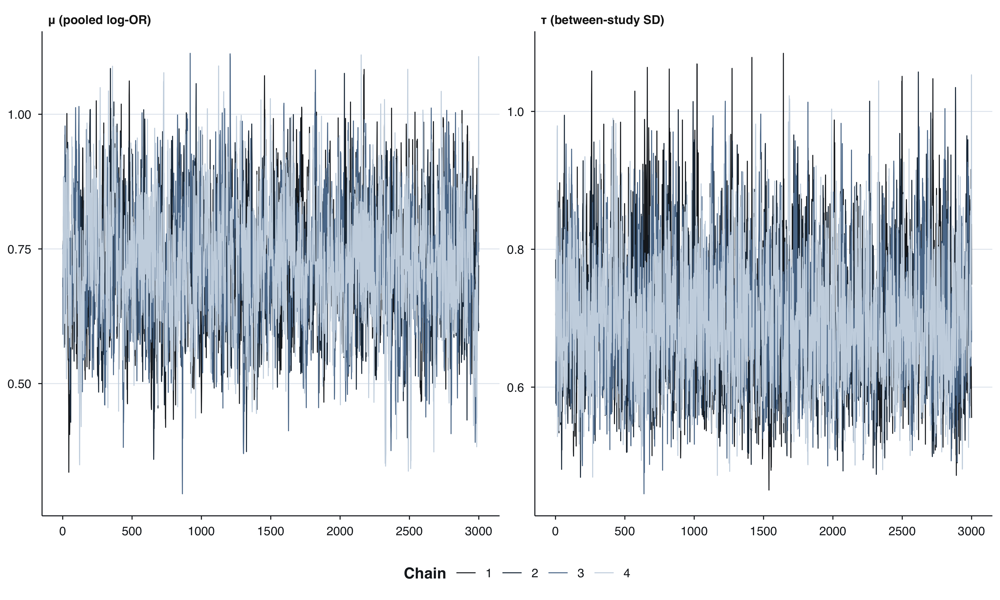

In [ ]:
#| label: fig-trace
#| fig-cap: "Trace plots for key parameters of the primary pooled model. Well-mixed chains (caterpillar appearance) indicate good convergence."
#| fig-height: 6
bayesplot::mcmc_trace(
  fits$fit_base,
  pars = c("b_Intercept", "sd_study_id__Intercept"),
  facet_args = list(labeller = as_labeller(c(
    b_Intercept              = "μ (pooled log-OR)",
    sd_study_id__Intercept   = "τ (between-study SD)"
  )))
) +
  theme_jama(base_size = 11)

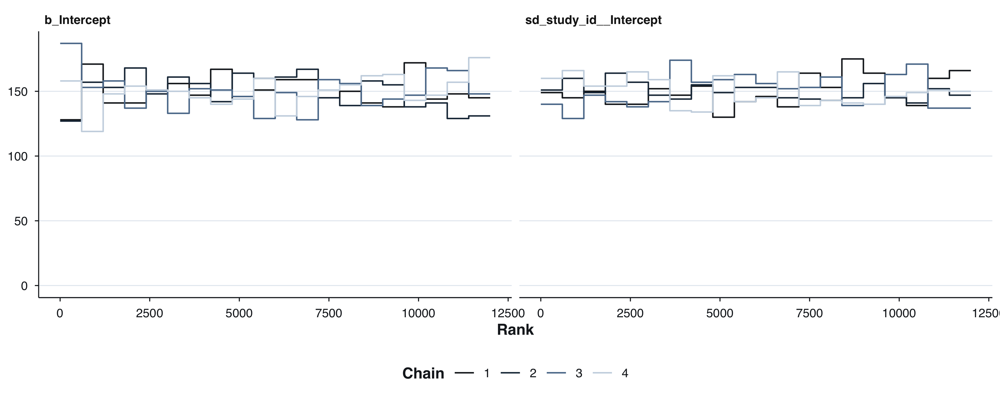

In [ ]:
#| label: fig-rank
#| fig-cap: "Rank histograms for key parameters. Uniform bars across all chains indicate no chain-mixing issues."
#| fig-height: 4
bayesplot::mcmc_rank_overlay(
  fits$fit_base,
  pars = c("b_Intercept", "sd_study_id__Intercept")
) +
  theme_jama(base_size = 11)

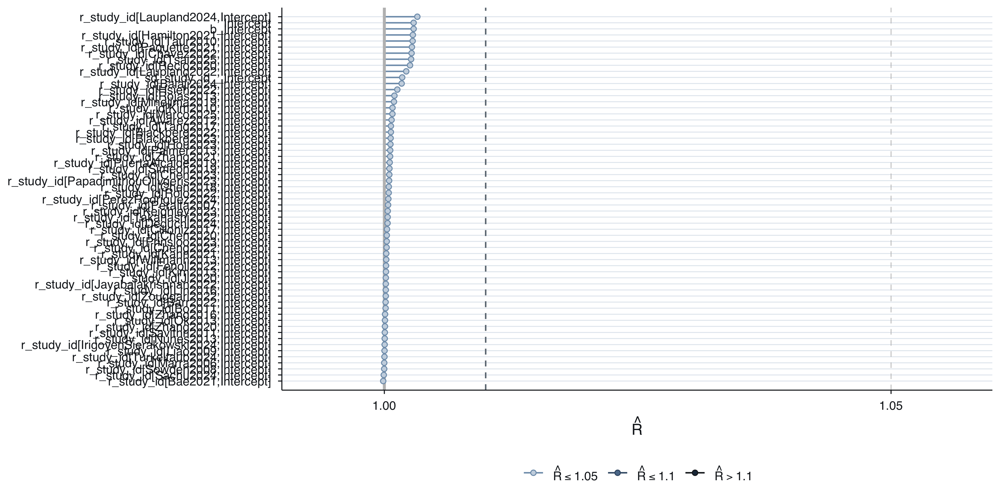

In [ ]:
#| label: fig-rhat
#| fig-cap: "R̂ dot plot for all parameters of the primary pooled model. All values should fall below 1.01 (dashed line)."
#| fig-height: 5
rhat_vals <- posterior::summarise_draws(fits$fit_base, rhat = posterior::rhat) |>
  filter(!grepl("^lp__|^lprior", variable)) |>
  (\(d) setNames(d$rhat, d$variable))()

bayesplot::mcmc_rhat(rhat_vals) +
  geom_vline(xintercept = 1.01, linetype = "dashed", color = jama_ref_line) +
  theme_jama(base_size = 11)

# Subgroup analysis — pathogen class

ℹ Please use `linewidth` instead.

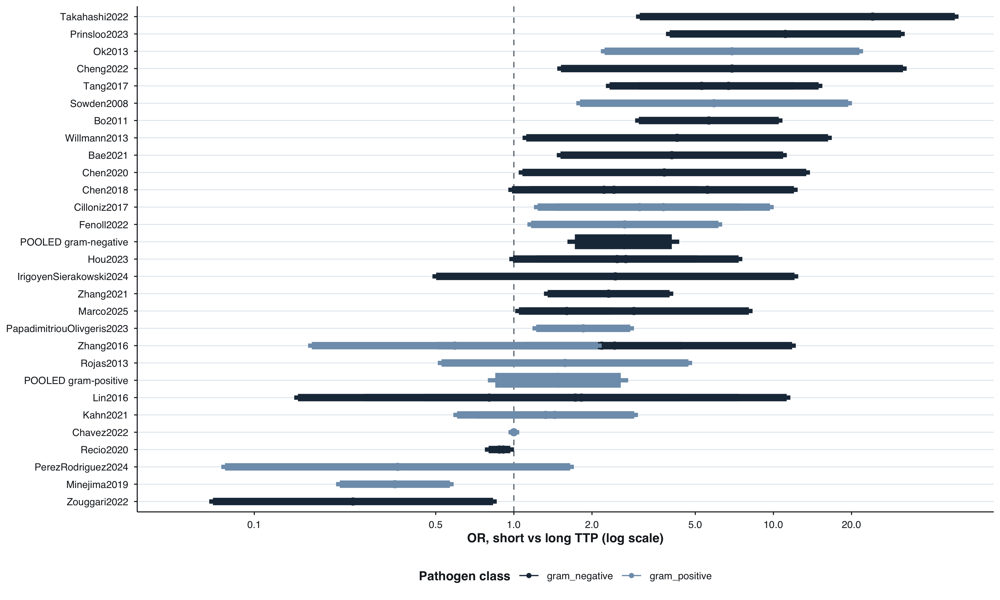

In [ ]:
#| label: fig-subgroup
#| fig-cap: "Forest plot stratified by pathogen class. Pooled estimates for each subgroup overlaid in bold."

# Only proceed if both subgroups fit
if (!is.null(fits$fit_gram_pos) && !is.null(fits$fit_gram_neg)) {
  gpos_post <- pooled_summary(fits$fit_gram_pos)
  gneg_post <- pooled_summary(fits$fit_gram_neg)

  sub_df <- es_mort |>
    filter(pathogen_class %in% c("gram_positive", "gram_negative")) |>
    mutate(or = exp(yi),
           ci_low = exp(yi - 1.96*sei),
           ci_high = exp(yi + 1.96*sei),
           type = "Study")

  pooled_sub <- tibble(
    study_id = c("POOLED gram-positive", "POOLED gram-negative"),
    pathogen_class = c("gram_positive", "gram_negative"),
    or = c(gpos_post$median_OR, gneg_post$median_OR),
    ci_low = c(gpos_post$ci_OR[1], gneg_post$ci_OR[1]),
    ci_high = c(gpos_post$ci_OR[2], gneg_post$ci_OR[2]),
    type = "Pooled"
  )

  ggplot(bind_rows(sub_df, pooled_sub),
         aes(x = or, y = reorder(study_id, or), color = pathogen_class, shape = type, size = type)) +
    geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
    geom_point() +
    geom_errorbar(aes(xmin = pmax(ci_low, 0.05), xmax = pmin(ci_high, 50)),
                  width = 0.25, orientation = "y") +
    scale_color_manual(values = c("gram_positive" = "#7F9DB9", "gram_negative" = "#1F3447")) +
    scale_shape_manual(values = c("Study" = 16, "Pooled" = 18), guide = "none") +
    scale_size_manual(values = c("Study" = 2.5, "Pooled" = 5), guide = "none") +
    scale_x_log10(breaks = c(0.1, 0.5, 1, 2, 5, 10, 20), limits = c(0.05, 50)) +
    labs(x = "OR, short vs long TTP (log scale)", y = NULL, color = "Pathogen class") +
    theme_jama(base_size = 9) +
    theme(legend.position = "bottom")
}

In [ ]:
#| label: tbl-subgroup
#| tbl-cap: "Pooled OR by pathogen subgroup."
if (!is.null(fits$fit_gram_pos) && !is.null(fits$fit_gram_neg)) {
  gpos_post <- pooled_summary(fits$fit_gram_pos)
  gneg_post <- pooled_summary(fits$fit_gram_neg)
  tibble(
    Subgroup = c("Gram-positive", "Gram-negative"),
    `N effect sizes` = c(nrow(filter(es_mort, pathogen_class == "gram_positive")),
                         nrow(filter(es_mort, pathogen_class == "gram_negative"))),
    `Median OR` = sprintf("%.2f", c(gpos_post$median_OR, gneg_post$median_OR)),
    `95% CrI`   = sprintf("[%.2f, %.2f]",
                          c(gpos_post$ci_OR[1], gneg_post$ci_OR[1]),
                          c(gpos_post$ci_OR[2], gneg_post$ci_OR[2])),
    `P(short TTP harmful)` = sprintf("%.1f%%",
                                     c(gpos_post$p_harm, gneg_post$p_harm) * 100)
  ) |> gt()
}

## Posterior densities by pathogen class

(`stat_slabinterval()`).

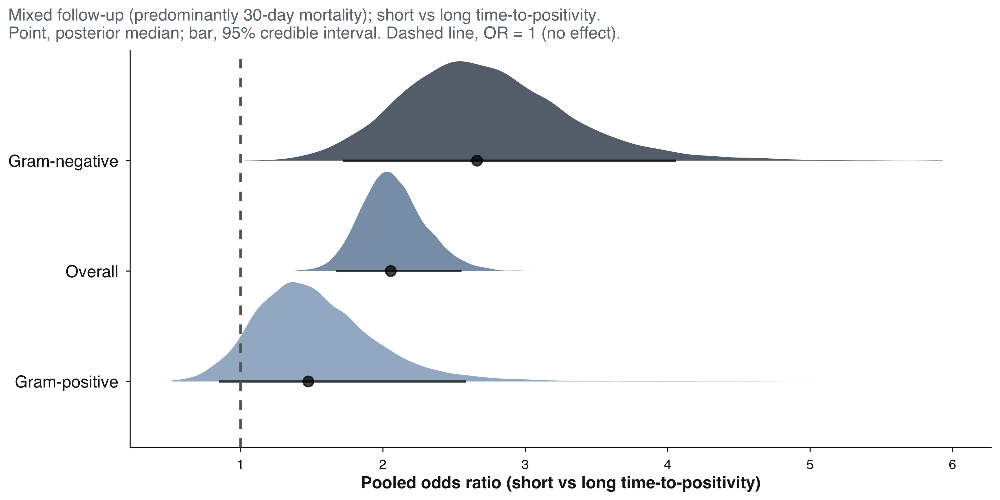

In [ ]:
#| label: fig-pathogen-posteriors
#| fig-cap: "**Figure 1.** Posterior distributions of the pooled odds ratio (OR) for all-cause mortality comparing short versus long time-to-positivity (TTP), stratified by pathogen class. Each density represents the full posterior from a Bayesian random-effects meta-analysis (72 mortality effect sizes; 100 studies). The filled point marks the posterior median; the horizontal bar spans the 95% credible interval (CrI). The vertical dashed line indicates OR = 1 (no effect). 'Short' and 'long' TTP were defined by individual studies using study-specific thresholds (median cutpoint 12 h; range 2–72 h). Outcome was predominantly 30-day mortality. Overall: OR = 2.06 (95% CrI 1.67–2.55); Gram-negative: OR = 2.66 (95% CrI 1.72–4.06); Gram-positive: OR = 1.48 (95% CrI 0.85–2.58). OR > 1 indicates higher mortality with shorter TTP."
#| fig-height: 5
if (!is.null(fits$fit_gram_pos) && !is.null(fits$fit_gram_neg)) {
  gpos_post <- pooled_summary(fits$fit_gram_pos)
  gneg_post <- pooled_summary(fits$fit_gram_neg)

  density_df <- bind_rows(
    tibble(OR = base_post$OR_draws, group = "Overall"),
    tibble(OR = gneg_post$OR_draws, group = "Gram-negative"),
    tibble(OR = gpos_post$OR_draws, group = "Gram-positive")
  ) |>
    mutate(group = factor(group,
                          levels = c("Gram-positive", "Overall", "Gram-negative")))

  ggplot(density_df, aes(x = OR, y = group, fill = group)) +
    stat_halfeye(alpha = 0.75, point_color = "black", point_size = 3,
                 interval_color = "black", interval_size = 2,
                 .width = 0.95, normalize = "xy") +
    geom_vline(xintercept = 1, linetype = "dashed",
               color = "gray40", linewidth = 0.8) +
    scale_fill_manual(
      values = c("Gram-positive" = "#7F9DB9",
                 "Overall"       = "#5B7A99",
                 "Gram-negative" = "#1F3447"),
      guide = "none") +
    scale_x_continuous(limits = c(0.5, 6), breaks = 1:6,
                       name = "Pooled odds ratio (short vs long time-to-positivity)") +
    labs(y = NULL,
         subtitle = "Mixed follow-up (predominantly 30-day mortality); short vs long time-to-positivity.\nPoint, posterior median; bar, 95% credible interval. Dashed line, OR = 1 (no effect).") +
    theme_jama(base_size = 12) +
    theme(panel.grid.major.y = element_blank(),
          panel.grid.minor   = element_blank(),
          axis.text.y        = element_text(size = 12))
}

# TTP cutpoint dose-response

(`geom_point()`).

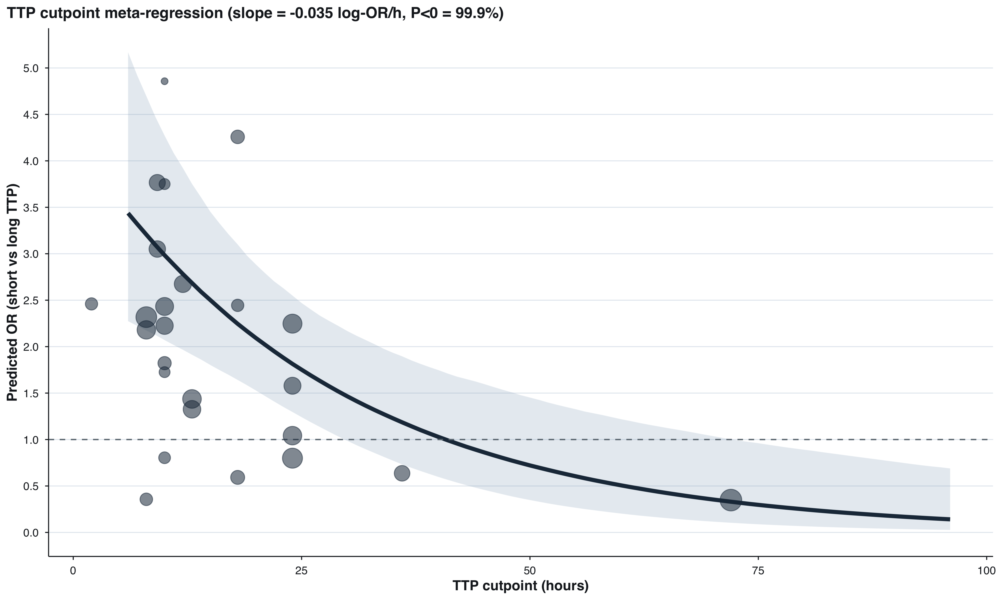

In [ ]:
#| label: fig-cutpoint
#| fig-cap: "TTP cutpoint meta-regression. The line is the Bayesian posterior median predicted OR by cutpoint; ribbon is the 95% CrI. Dark points are observed 2×2-derived effect sizes (size ∝ precision)."

if (!is.null(fits$fit_cutpoint)) {
  draws <- as_draws_df(fits$fit_cutpoint)
  med_cp <- median(es_mort$ttp_cutpoint_hours[es_mort$es_source == "two_by_two"], na.rm = TRUE)
  range_cp <- seq(6, 96, by = 1)
  pred_df <- map_dfr(range_cp, function(cp) {
    centered <- cp - med_cp
    logOR <- draws$b_Intercept + draws$b_cutpoint_c * centered
    tibble(cutpoint = cp,
           median_OR = median(exp(logOR)),
           lo = quantile(exp(logOR), 0.025),
           hi = quantile(exp(logOR), 0.975))
  })

  obs_df <- es_mort |>
    filter(es_source == "two_by_two", !is.na(ttp_cutpoint_hours)) |>
    mutate(or = exp(yi), w = 1/sei)

  slope_p_neg <- mean(draws$b_cutpoint_c < 0) * 100
  slope_med <- median(draws$b_cutpoint_c)

  ggplot(pred_df, aes(x = cutpoint, y = median_OR)) +
    geom_ribbon(aes(ymin = lo, ymax = hi), fill = "#7F9DB9", alpha = 0.2) +
    geom_line(color = "#1F3447", linewidth = 1.4) +
    geom_hline(yintercept = 1, linetype = "dashed", color = jama_ref_line) +
    geom_point(data = obs_df,
               aes(x = ttp_cutpoint_hours, y = or, size = w),
               alpha = 0.55, color = "#1F3447", inherit.aes = FALSE) +
    scale_size_continuous(range = c(2, 7), guide = "none") +
    scale_y_continuous(limits = c(0, max(5, max(pred_df$hi, na.rm = TRUE))),
                       breaks = seq(0, 10, 0.5)) +
    labs(title = sprintf("TTP cutpoint meta-regression (slope = %.3f log-OR/h, P<0 = %.1f%%)",
                         slope_med, slope_p_neg),
         x = "TTP cutpoint (hours)",
         y = "Predicted OR (short vs long TTP)") +
    theme_jama()
}

## Gram-negative cutpoint dose-response

In [ ]:
#| label: gneg-cutpoint-setup
#| include: false
es_gneg_mort <- es_mort |> filter(pathogen_class == "gram_negative")
es_gneg_cut  <- es_gneg_mort |>
  filter(es_source == "two_by_two", !is.na(ttp_cutpoint_hours)) |>
  mutate(cutpoint_c = ttp_cutpoint_hours - median(ttp_cutpoint_hours))

gneg_cut_path <- "_brms_cache/primary/fit_gneg_cutpoint"
fit_gneg_cut  <- brm(
  formula    = bf(yi | se(sei) ~ 1 + cutpoint_c + (1 | study_id)),
  data       = es_gneg_cut,
  prior      = c(prior(normal(0, 1),   class = "Intercept"),
                 prior(cauchy(0, 0.5), class = "sd"),
                 prior(normal(0, 0.5), class = "b")),
  chains = 4, iter = 4000, warmup = 1000,
  cores  = parallel::detectCores(),
  control = list(adapt_delta = 0.99, max_treedepth = 12),
  seed = 7421, file = gneg_cut_path, file_refit = "on_change",
  silent = 2, refresh = 0
)

draws_gneg_cut <- as_draws_df(fit_gneg_cut)
med_cp_gneg    <- median(es_gneg_cut$ttp_cutpoint_hours)
roc_cuts_gneg  <- es_gneg_cut |>
  filter(ttp_cutpoint_basis == "ROC_derived") |>
  pull(ttp_cutpoint_hours) |> unique() |> sort()

pred_gneg <- map_dfr(seq(2, 30, by = 0.5), function(cp) {
  logOR <- draws_gneg_cut$b_Intercept +
           draws_gneg_cut$b_cutpoint_c * (cp - med_cp_gneg)
  tibble(cutpoint  = cp,
         median_OR = median(exp(logOR)),
         lo        = quantile(exp(logOR), 0.025),
         hi        = quantile(exp(logOR), 0.975))
})

Warning in log(x, base): NaNs produced

(`geom_ribbon()`).

(`geom_point()`).

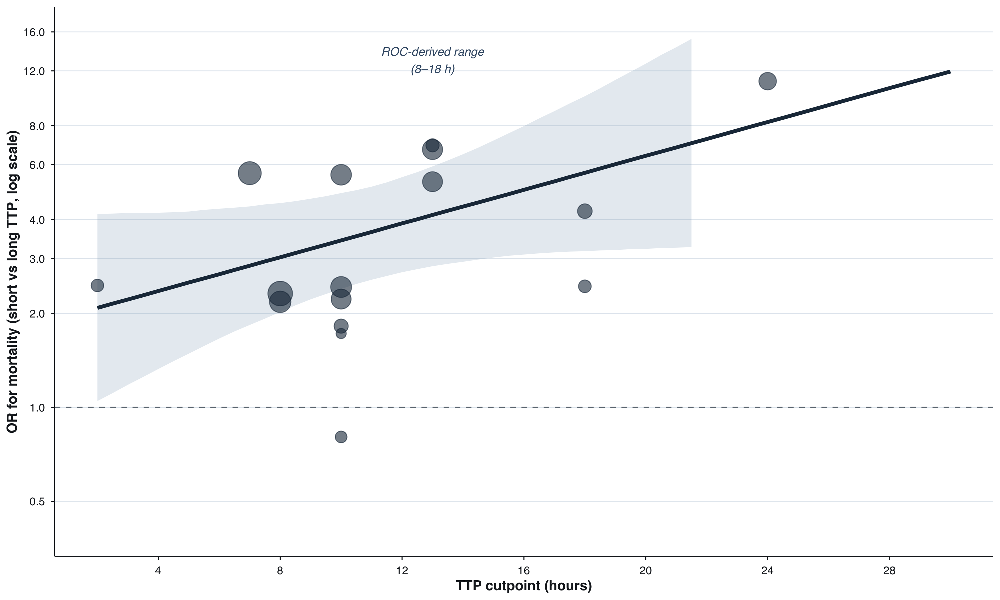

In [ ]:
#| label: fig-gneg-cutpoint
#| fig-cap: "TTP cutpoint dose-response for Gram-negative bacteremia. The curve is the Bayesian posterior median predicted OR; ribbon is the 95% CrI. Dark points are 2×2-derived effect sizes (size ∝ precision). Shaded zone spans the range of ROC-derived optimal cutpoints reported in individual Gram-negative studies (8–18 h). The median cutpoint across studies is 10 h."

obs_gneg_cp <- es_gneg_cut |> mutate(or = exp(yi), w = 1 / sei)

ggplot(pred_gneg, aes(x = cutpoint, y = median_OR)) +
  annotate("rect", xmin = min(roc_cuts_gneg), xmax = max(roc_cuts_gneg),
           ymin = -Inf, ymax = Inf, fill = "#E3E9EF", alpha = 0.6) +
  annotate("text", x = mean(range(roc_cuts_gneg)), y = 13,
           label = "ROC-derived range\n(8–18 h)", size = 3,
           color = "#3F5A75", fontface = "italic") +
  geom_ribbon(aes(ymin = lo, ymax = hi), fill = "#7F9DB9", alpha = 0.2) +
  geom_line(color = "#1F3447", linewidth = 1.3) +
  geom_hline(yintercept = 1, linetype = "dashed", color = jama_ref_line) +
  geom_point(data = obs_gneg_cp,
             aes(x = ttp_cutpoint_hours, y = or, size = w),
             alpha = 0.6, color = "#1F3447", inherit.aes = FALSE) +
  scale_size_continuous(range = c(2, 8), guide = "none") +
  scale_y_continuous(limits = c(0.4, 16), trans = "log10",
                     breaks = c(0.5, 1, 2, 3, 4, 6, 8, 12, 16)) +
  scale_x_continuous(breaks = seq(0, 30, 4)) +
  labs(x = "TTP cutpoint (hours)",
       y = "OR for mortality (short vs long TTP, log scale)") +
  theme_jama() +
  theme(panel.grid.minor = element_blank())

In [ ]:
#| label: tbl-gneg-cutpoint
#| tbl-cap: "Gram-negative cutpoint meta-regression slope and predicted OR at key thresholds."
d_gneg <- as_draws_df(fit_gneg_cut)
bind_rows(
  tibble(
    Parameter   = "Slope (log-OR per hour above median)",
    Estimate    = sprintf("%.3f", median(d_gneg$b_cutpoint_c)),
    `95% CrI`   = sprintf("[%.3f, %.3f]",
                           quantile(d_gneg$b_cutpoint_c, 0.025),
                           quantile(d_gneg$b_cutpoint_c, 0.975)),
    `P(direction)` = sprintf("%.1f%%", mean(d_gneg$b_cutpoint_c > 0) * 100)
  ),
  map_dfr(c(8, 10, 13, 18), function(cp) {
    logOR <- d_gneg$b_Intercept + d_gneg$b_cutpoint_c * (cp - med_cp_gneg)
    tibble(
      Parameter      = sprintf("Predicted OR at cutpoint %d h", cp),
      Estimate       = sprintf("%.2f", median(exp(logOR))),
      `95% CrI`      = sprintf("[%.2f, %.2f]",
                                quantile(exp(logOR), 0.025),
                                quantile(exp(logOR), 0.975)),
      `P(direction)` = sprintf("%.1f%%", mean(exp(logOR) > 1) * 100)
    )
  })
) |> gt()

## Gram-positive cutpoint dose-response

In [ ]:
#| label: gpos-cutpoint-setup
#| include: false
es_gpos_mort <- es_mort |> filter(pathogen_class == "gram_positive")
es_gpos_cut  <- es_gpos_mort |>
  filter(es_source == "two_by_two", !is.na(ttp_cutpoint_hours)) |>
  mutate(cutpoint_c = ttp_cutpoint_hours - median(ttp_cutpoint_hours))

es_gpos_cut_sens <- es_gpos_cut |>
  filter(study_id != "Minejima2019") |>
  mutate(cutpoint_c = ttp_cutpoint_hours - median(ttp_cutpoint_hours))

gpos_cut_path <- "_brms_cache/primary/fit_gpos_cutpoint"
fit_gpos_cut  <- brm(
  formula    = bf(yi | se(sei) ~ 1 + cutpoint_c + (1 | study_id)),
  data       = es_gpos_cut,
  prior      = c(prior(normal(0, 1),   class = "Intercept"),
                 prior(cauchy(0, 0.5), class = "sd"),
                 prior(normal(0, 0.5), class = "b")),
  chains = 4, iter = 4000, warmup = 1000,
  cores  = parallel::detectCores(),
  control = list(adapt_delta = 0.99, max_treedepth = 12),
  seed = 3817, file = gpos_cut_path, file_refit = "on_change",
  silent = 2, refresh = 0
)

gpos_cut_sens_path <- "_brms_cache/primary/fit_gpos_cutpoint_sens"
fit_gpos_cut_sens  <- brm(
  formula    = bf(yi | se(sei) ~ 1 + cutpoint_c + (1 | study_id)),
  data       = es_gpos_cut_sens,
  prior      = c(prior(normal(0, 1),   class = "Intercept"),
                 prior(cauchy(0, 0.5), class = "sd"),
                 prior(normal(0, 0.5), class = "b")),
  chains = 4, iter = 4000, warmup = 1000,
  cores  = parallel::detectCores(),
  control = list(adapt_delta = 0.99, max_treedepth = 12),
  seed = 5294, file = gpos_cut_sens_path, file_refit = "on_change",
  silent = 2, refresh = 0
)

draws_gpos_cut <- as_draws_df(fit_gpos_cut)
d_sens_gpos    <- as_draws_df(fit_gpos_cut_sens)
med_cp_gpos    <- median(es_gpos_cut$ttp_cutpoint_hours)
med_cp_sens_gpos <- median(es_gpos_cut_sens$ttp_cutpoint_hours)
roc_cuts_gpos  <- es_gpos_cut |>
  filter(ttp_cutpoint_basis == "ROC_derived", ttp_cutpoint_hours < 30) |>
  pull(ttp_cutpoint_hours) |> unique() |> sort()

pred_gpos_cp <- map_dfr(seq(6, 30, by = 0.5), function(cp) {
  logOR <- draws_gpos_cut$b_Intercept +
           draws_gpos_cut$b_cutpoint_c * (cp - med_cp_gpos)
  tibble(cutpoint = cp, model = "Full (8–72 h)",
         median_OR = median(exp(logOR)),
         lo = quantile(exp(logOR), 0.025),
         hi = quantile(exp(logOR), 0.975))
})
pred_gpos_sens_cp <- map_dfr(seq(6, 30, by = 0.5), function(cp) {
  logOR <- d_sens_gpos$b_Intercept +
           d_sens_gpos$b_cutpoint_c * (cp - med_cp_sens_gpos)
  tibble(cutpoint = cp, model = "Sensitivity (excl. Minejima2019)",
         median_OR = median(exp(logOR)),
         lo = quantile(exp(logOR), 0.025),
         hi = quantile(exp(logOR), 0.975))
})

Warning in log(x, base): NaNs produced

(`geom_ribbon()`).

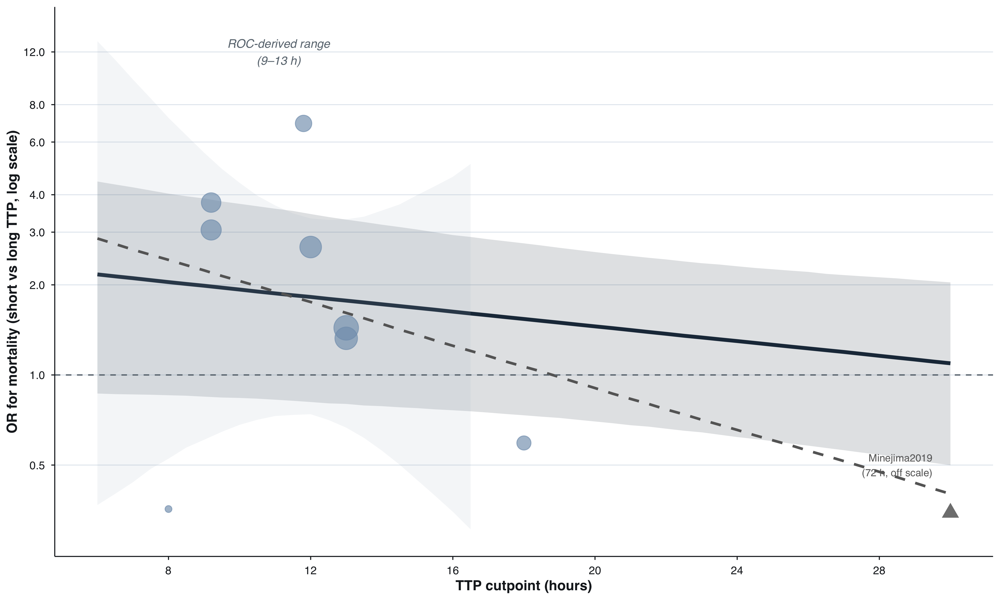

In [ ]:
#| label: fig-gpos-cutpoint
#| fig-cap: "TTP cutpoint dose-response for Gram-positive bacteremia. Solid curve = full model (8–72 h); dashed gray = sensitivity excluding Minejima2019 (72 h), which uses a biologically distinct definition of prolonged bacteremia. Light points are 2×2-derived effect sizes. Shaded zone = range of ROC-derived cutpoints from Gram-positive studies (9–13 h). The negative slope in the full model is driven almost entirely by Minejima2019; after exclusion the slope becomes uncertain (P[slope < 0] = 75%)."

obs_gpos_cp <- es_gpos_cut |>
  filter(ttp_cutpoint_hours <= 30) |>
  mutate(or = exp(yi), w = 1 / sei)

ggplot(pred_gpos_cp, aes(x = cutpoint, y = median_OR)) +
  annotate("rect", xmin = min(roc_cuts_gpos), xmax = max(roc_cuts_gpos),
           ymin = -Inf, ymax = Inf, fill = "#E3E9EF", alpha = 0.65) +
  annotate("text", x = mean(range(roc_cuts_gpos)), y = 12,
           label = "ROC-derived range\n(9–13 h)", size = 3,
           color = "#6B7680", fontface = "italic") +
  geom_ribbon(aes(ymin = lo, ymax = hi), fill = "#1F3447", alpha = 0.15, color = NA) +
  geom_line(color = "#1F3447", linewidth = 1.3) +
  geom_ribbon(data = pred_gpos_sens_cp,
              aes(ymin = lo, ymax = hi), fill = "#A9BBCB", alpha = 0.12, color = NA) +
  geom_line(data = pred_gpos_sens_cp,
            color = "gray40", linewidth = 0.9, linetype = "dashed") +
  geom_hline(yintercept = 1, linetype = "dashed", color = jama_ref_line) +
  geom_point(data = obs_gpos_cp,
             aes(x = ttp_cutpoint_hours, y = or, size = w),
             alpha = 0.65, color = "#7F9DB9", inherit.aes = FALSE) +
  # Flag truncated 72h outlier
  annotate("point", x = 30, y = exp(-1.06), size = 4, color = "gray50", shape = 17) +
  annotate("text", x = 29.5, y = 0.5,
           label = "Minejima2019\n(72 h, off scale)", size = 2.6,
           color = "gray40", hjust = 1) +
  scale_size_continuous(range = c(2, 8), guide = "none") +
  scale_y_continuous(limits = c(0.3, 14), trans = "log10",
                     breaks = c(0.5, 1, 2, 3, 4, 6, 8, 12)) +
  scale_x_continuous(breaks = seq(0, 30, 4), limits = c(6, 30)) +
  labs(x = "TTP cutpoint (hours)",
       y = "OR for mortality (short vs long TTP, log scale)") +
  theme_jama() +
  theme(panel.grid.minor = element_blank())

In [ ]:
#| label: tbl-gpos-cutpoint
#| tbl-cap: "Gram-positive cutpoint meta-regression: slope comparison between full model and sensitivity analysis excluding Minejima2019 (72 h)."
tibble(
  Model       = c("Full (8–72 h)", "Sensitivity (excl. Minejima2019)"),
  `N studies` = c(n_distinct(es_gpos_cut$study_id),
                  n_distinct(es_gpos_cut_sens$study_id)),
  `Slope (log-OR/h)` = c(
    sprintf("%.3f [%.3f, %.3f]",
            median(draws_gpos_cut$b_cutpoint_c),
            quantile(draws_gpos_cut$b_cutpoint_c, 0.025),
            quantile(draws_gpos_cut$b_cutpoint_c, 0.975)),
    sprintf("%.3f [%.3f, %.3f]",
            median(d_sens_gpos$b_cutpoint_c),
            quantile(d_sens_gpos$b_cutpoint_c, 0.025),
            quantile(d_sens_gpos$b_cutpoint_c, 0.975))
  ),
  `P(slope < 0)` = c(
    sprintf("%.1f%%", mean(draws_gpos_cut$b_cutpoint_c  < 0) * 100),
    sprintf("%.1f%%", mean(d_sens_gpos$b_cutpoint_c < 0) * 100)
  )
) |> gt()

# Continuous TTP dose-response

The analyses above summarise how the *dichotomised* TTP cutpoint moderates the pooled OR. Here we model the **continuous, within-patient relationship** between TTP and mortality using a simulation-assisted approach. Because individual patient data are unavailable, representative TTP values for each study’s short and long groups are estimated from a truncated log-normal distribution calibrated to the TTP literature (Gram-negative: median 13 h, σ = 0.55; Gram-positive: median 15 h, σ = 0.55). A mixed-effects logistic regression (GLMM, `lme4`) is then fitted to the resulting group-level mortality rates, with study random intercepts. The resulting dose-response slope is expressed as the log-OR per unit of log-TTP — equivalent to a multiplicative OR per doubling of TTP.

In [ ]:
#| label: continuous-dr-setup
#| include: false
library(lme4)


Attaching package: 'lme4'

The following object is masked from 'package:brms':

    ngrps

## Combined pathogen-class OR curves

(`geom_ribbon()`).

(`geom_line()`).

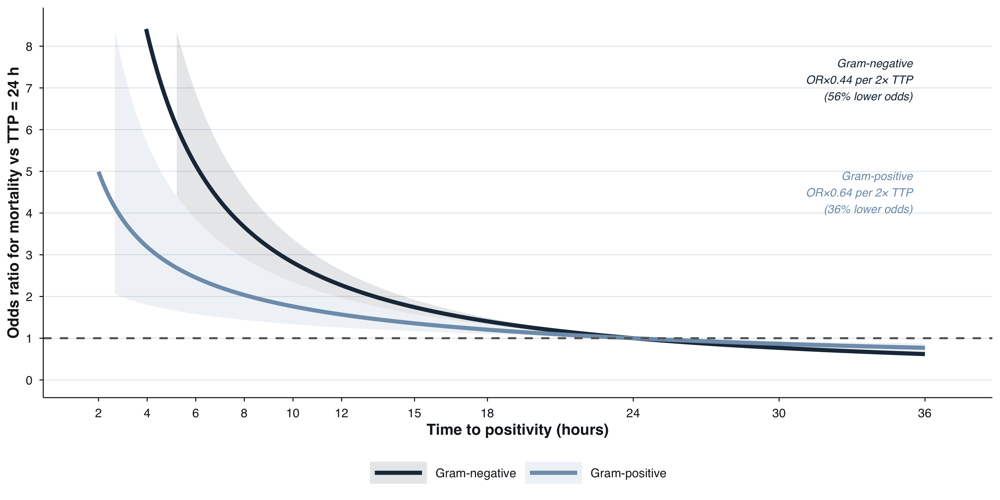

In [ ]:
#| label: fig-dr-overlay
#| fig-height: 5
#| fig-cap: "Continuous TTP dose-response for mortality: Gram-negative (dark navy) vs Gram-positive (light blue-grey) bacteremia. OR expressed relative to TTP = 24 h (dashed reference line). Shaded bands are 95% confidence intervals on the dose-response slope. Each doubling of TTP was associated with a 56% reduction in mortality odds in Gram-negative bacteremia (OR per 2× TTP = 0.44, 95% CI 0.38–0.51) and a 36% reduction in Gram-positive bacteremia (OR per 2× TTP = 0.64, 95% CI 0.51–0.80). Model: simulation-assisted mixed-effects logistic regression; representative TTP estimated from truncated log-normal distributions. Gram-negative: Prinsloo2023 excluded (anomalous group composition at 24 h cutpoint). Gram-positive: Minejima2019 excluded (72 h cutpoint reflects persistent bacteremia, a biologically distinct signal)."

bind_rows(curve_gneg, curve_gpos) |>
  ggplot(aes(x = ttp, y = median_OR, color = gram, fill = gram)) +
  geom_ribbon(aes(ymin = lo, ymax = hi), alpha = 0.12, color = NA) +
  geom_line(linewidth = 1.4) +
  geom_hline(yintercept = 1, linetype = "dashed",
             color = "gray40", linewidth = 0.7) +
  annotate("text", x = 35.5, y = 7.2,
           label = "Gram-negative\nOR×0.44 per 2× TTP\n(56% lower odds)",
           size = 2.9, color = "#1F3447", hjust = 1, fontface = "italic") +
  annotate("text", x = 35.5, y = 4.5,
           label = "Gram-positive\nOR×0.64 per 2× TTP\n(36% lower odds)",
           size = 2.9, color = "#7F9DB9", hjust = 1, fontface = "italic") +
  scale_color_manual(values = c("Gram-negative" = "#1F3447",
                                "Gram-positive" = "#7F9DB9")) +
  scale_fill_manual( values = c("Gram-negative" = "#1F3447",
                                "Gram-positive" = "#7F9DB9")) +
  scale_x_continuous(breaks = c(2, 4, 6, 8, 10, 12, 15, 18, 24, 30, 36),
                     limits = c(1.5, 37),
                     name   = "Time to positivity (hours)") +
  scale_y_continuous(limits = c(0, 8.5), breaks = 0:8,
                     name   = "Odds ratio for mortality vs TTP = 24 h") +
  labs(color = NULL, fill = NULL) +
  theme_jama(base_size = 11) +
  theme(panel.grid.minor = element_blank(),
        legend.position  = "bottom",
        legend.key.width = unit(1.5, "cm"))

## Gram-specific dose-response: OR and absolute mortality

(`geom_ribbon()`).

(`geom_line()`).

Warning in geom_point(aes(x = anchor$ref_ttp, y = anchor$mort * 100), color = col, : All aesthetics have length 1, but the data has 200 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.

(`geom_ribbon()`).

(`geom_line()`).

(`geom_point()`).

(`geom_ribbon()`).

Warning in geom_point(aes(x = anchor$ref_ttp, y = anchor$mort * 100), color = col, : All aesthetics have length 1, but the data has 200 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.

(`geom_ribbon()`).

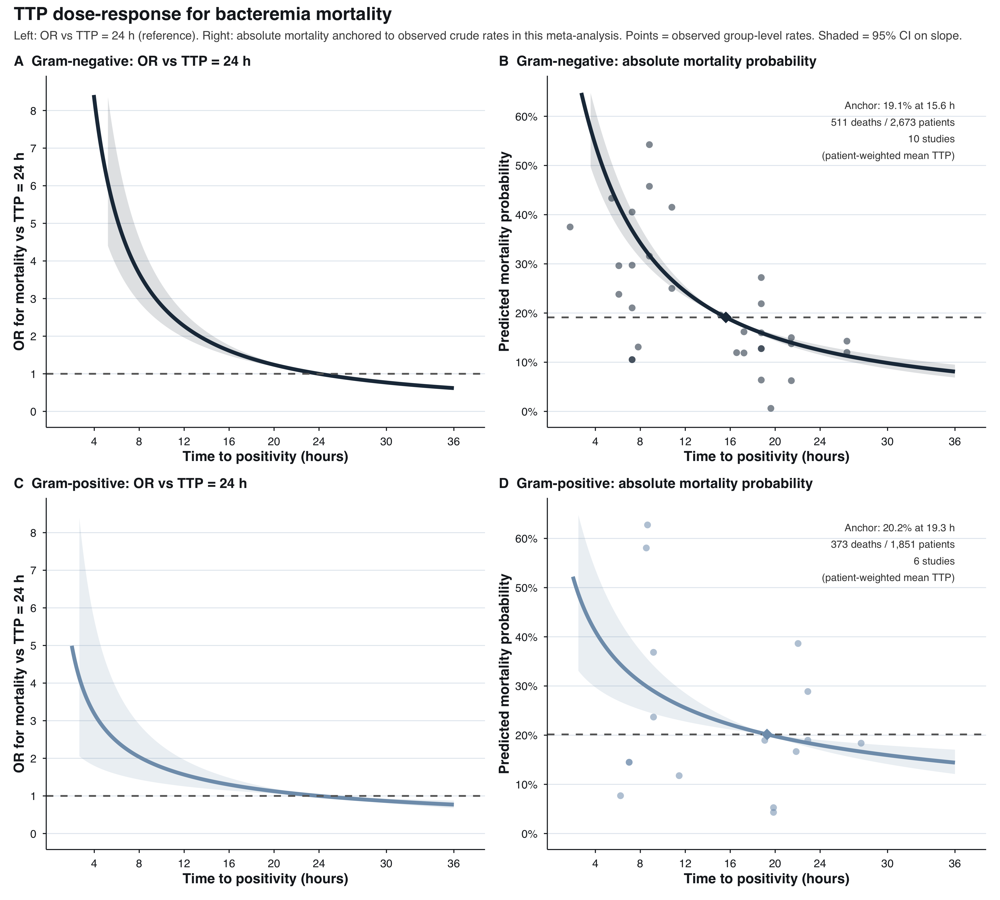

In [ ]:
#| label: fig-dr-fourpanel
#| fig-height: 9
#| fig-cap: "**Figure 2.** Continuous TTP dose-response for bacteremia mortality, stratified by pathogen class. Curves estimated using a simulation-assisted mixed-effects logistic regression applied to 2×2-table study data; representative TTP values for each study's short and long groups derived from truncated log-normal distributions (Gram-negative: median 13 h; Gram-positive: median 15 h). **Panels A and C** show the predicted odds ratio for mortality relative to TTP = 24 h (dashed reference line) for Gram-negative and Gram-positive bacteremia, respectively. **Panels B and D** show predicted absolute mortality probability anchored to observed crude mortality rates from the 2×2 studies (Gram-negative: 18.6% at patient-weighted mean TTP 15.6 h, 534 deaths/2,866 patients, 11 studies; Gram-positive: 20.2% at 19.3 h, 373 deaths/1,851 patients, 6 studies); the diamond marks the anchor point and the dashed line the baseline mortality. Scatter points are observed group-level mortality rates from individual studies. Shaded bands are 95% confidence intervals reflecting uncertainty in the dose-response slope. Each doubling of TTP was associated with a 56% reduction in mortality odds in Gram-negative bacteremia (OR per 2× TTP = 0.44, 95% CI 0.38–0.51) and a 36% reduction in Gram-positive bacteremia (OR per 2× TTP = 0.64, 95% CI 0.51–0.80). TTP, time-to-positivity; OR, odds ratio; CI, confidence interval."

library(patchwork)
(p_or_gneg | p_prob_gneg) /
  (p_or_gpos | p_prob_gpos) +
  plot_annotation(
    title    = "TTP dose-response for bacteremia mortality",
    subtitle = paste0(
      "Left: OR vs TTP = 24 h (reference). ",
      "Right: absolute mortality anchored to observed crude rates in this meta-analysis. ",
      "Points = observed group-level rates. Shaded = 95% CI on slope."
    ),
    theme = theme(
      plot.title    = element_text(face = "bold", size = 13),
      plot.subtitle = element_text(size = 8.5, color = "gray30")
    )
  )

In [ ]:
#| label: tbl-dr-summary
#| tbl-cap: "Summary of continuous TTP dose-response estimates by pathogen class."
tibble(
  `Pathogen class`       = c("Gram-negative", "Gram-positive"),
  `Studies (N)`          = c(n_distinct(dose_df_gneg$study_id),
                              n_distinct(dose_df_gpos$study_id)),
  `Patients (N)`         = c(format(anc_gneg$n_pts, big.mark = ","),
                              format(anc_gpos$n_pts, big.mark = ",")),
  `Crude mortality`      = c(sprintf("%.1f%%", anc_gneg$mort * 100),
                              sprintf("%.1f%%", anc_gpos$mort * 100)),
  `β (log-OR/log-TTP)`   = c(sprintf("%.3f", b1_gneg), sprintf("%.3f", b1_gpos)),
  `OR per 2× TTP (95% CI)` = c(
    sprintf("%.2f (%.2f–%.2f)", exp(b1_gneg * log(2)),
            exp((b1_gneg - 1.96*sqrt(vc_gneg[2,2])) * log(2)),
            exp((b1_gneg + 1.96*sqrt(vc_gneg[2,2])) * log(2))),
    sprintf("%.2f (%.2f–%.2f)", exp(b1_gpos * log(2)),
            exp((b1_gpos - 1.96*sqrt(vc_gpos[2,2])) * log(2)),
            exp((b1_gpos + 1.96*sqrt(vc_gpos[2,2])) * log(2)))
  ),
  `Mortality reduction per 2× TTP` = c(
    sprintf("%.0f%%", (1 - exp(b1_gneg * log(2))) * 100),
    sprintf("%.0f%%", (1 - exp(b1_gpos * log(2))) * 100)
  ),
  `OR at 5 h vs 24 h`  = c(sprintf("%.1f×", (5/24)^b1_gneg),
                             sprintf("%.1f×", (5/24)^b1_gpos)),
  `OR at 10 h vs 24 h` = c(sprintf("%.1f×", (10/24)^b1_gneg),
                             sprintf("%.1f×", (10/24)^b1_gpos))
) |>
  gt() |>
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_column_labels())

# Publication bias

In [ ]:
#| label: pub-bias-setup
#| include: false
# Fit a frequentist RE model for Egger's test (REML, same data as primary Bayesian model)
rma_mort <- metafor::rma(yi = yi, sei = sei, data = es_mort, method = "REML")
mu_pool  <- as.numeric(coef(rma_mort))
egger    <- metafor::regtest(rma_mort, model = "lm")

## Contour-enhanced funnel plot

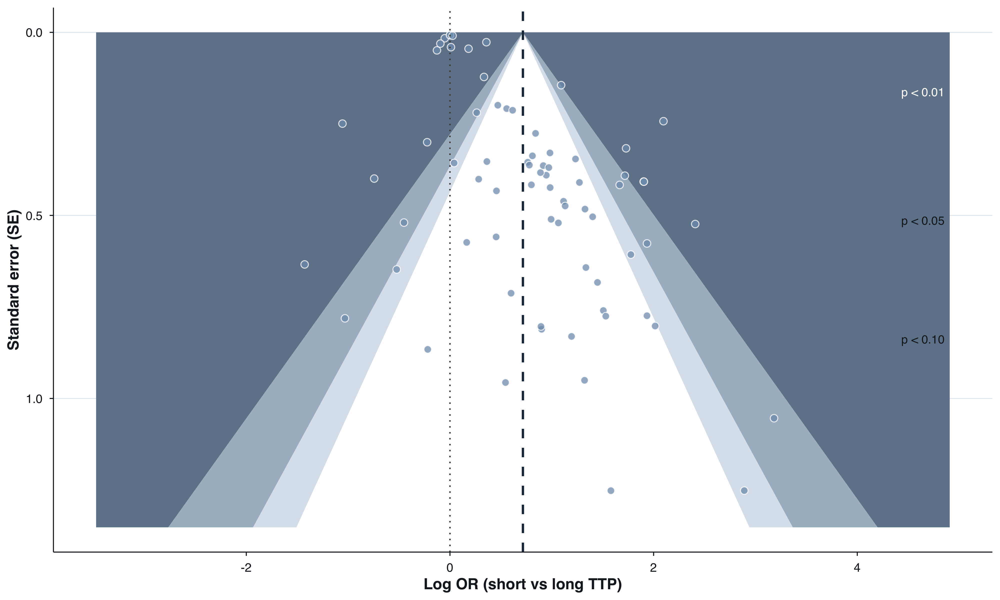

In [ ]:
#| label: fig-funnel
#| fig-cap: "Contour-enhanced funnel plot (primary pool, mortality). Studies in white zones are not statistically significant at the labelled threshold; shaded outer zones indicate increasing levels of significance. Asymmetry toward the right (short TTP harmful) would suggest positive-result publication bias."
#| fig-height: 6

max_se  <- max(es_mort$sei, na.rm = TRUE) * 1.08
se_seq  <- seq(0, max_se, length.out = 400)
x_lo    <- mu_pool - 3.1 * max_se
x_hi    <- mu_pool + 3.1 * max_se

contours <- tibble(se = se_seq) |>
  mutate(
    lo01 = mu_pool - 2.576 * se,  hi01 = mu_pool + 2.576 * se,
    lo05 = mu_pool - 1.96  * se,  hi05 = mu_pool + 1.96  * se,
    lo10 = mu_pool - 1.645 * se,  hi10 = mu_pool + 1.645 * se
  )

ggplot() +
  # Shaded significance regions (draw outermost first, then overwrite inward)
  geom_ribbon(data = contours,
              aes(y = se, xmin = x_lo,  xmax = lo01), fill = "#6F8499") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = hi01,  xmax = x_hi), fill = "#6F8499") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = lo01,  xmax = lo05), fill = "#A9BBCB") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = hi05,  xmax = hi01), fill = "#A9BBCB") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = lo05,  xmax = lo10), fill = "#DCE4EC") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = hi10,  xmax = hi05), fill = "#DCE4EC") +
  geom_ribbon(data = contours,
              aes(y = se, xmin = lo10,  xmax = hi10), fill = "white") +
  # Study points
  geom_point(data = es_mort, aes(x = yi, y = sei),
             shape = 21, fill = "#7F9DB9", color = "white",
             size = 2.2, alpha = 0.75) +
  # Pooled estimate (REML)
  geom_vline(xintercept = mu_pool, linetype = "dashed", color = "#1F3447", linewidth = 0.8) +
  # Null line
  geom_vline(xintercept = 0, linetype = "dotted", color = "gray30") +
  # Contour labels
  annotate("text", x = x_hi - 0.05, y = max_se * 0.12,
           label = "p < 0.01", hjust = 1, size = 3, color = "white") +
  annotate("text", x = x_hi - 0.05, y = max_se * 0.38,
           label = "p < 0.05", hjust = 1, size = 3, color = "#1A1F24") +
  annotate("text", x = x_hi - 0.05, y = max_se * 0.62,
           label = "p < 0.10", hjust = 1, size = 3, color = "#1A1F24") +
  scale_y_reverse(limits = c(max_se, 0),
                  name = "Standard error (SE)") +
  scale_x_continuous(limits = c(x_lo, x_hi),
                     name = "Log OR (short vs long TTP)") +
  theme_jama(base_size = 11) +
  theme(panel.grid.minor = element_blank())

## Egger’s test

In [ ]:
#| label: tbl-egger
#| tbl-cap: "Egger's regression test for funnel-plot asymmetry (primary pool, mortality; metafor::regtest, weighted regression on the standard error). The t-statistic tests asymmetry; the limit estimate is the predicted effect for a hypothetical study with zero standard error."
tibble(
  Statistic = c("Asymmetry test t-statistic", "df", "p-value",
                "Limit estimate as SE -> 0 (log OR)", "95% CI (log OR)",
                "Limit estimate as SE -> 0 (OR)"),
  Value = c(
    sprintf("%.2f", egger$zval),
    sprintf("%.0f", egger$ddf),
    format.pval(egger$pval, digits = 2, eps = 1e-4),
    sprintf("%.3f", egger$est),
    sprintf("[%.3f, %.3f]", egger$ci.lb, egger$ci.ub),
    sprintf("%.2f", exp(egger$est))
  )
) |> gt()

> **Interpreting Egger’s test in this context**
>
> Egger’s test has known limitations when between-study heterogeneity is high (as here): the test can flag asymmetry that reflects genuine heterogeneity rather than publication bias. Evidence of asymmetry should be followed up by examining whether small-study effects correlate with identifiable moderators (e.g., pathogen class, adjustment status) before attributing asymmetry to selective reporting.

# Sensitivity analyses

## Including the inclusive-pool studies (n=140)

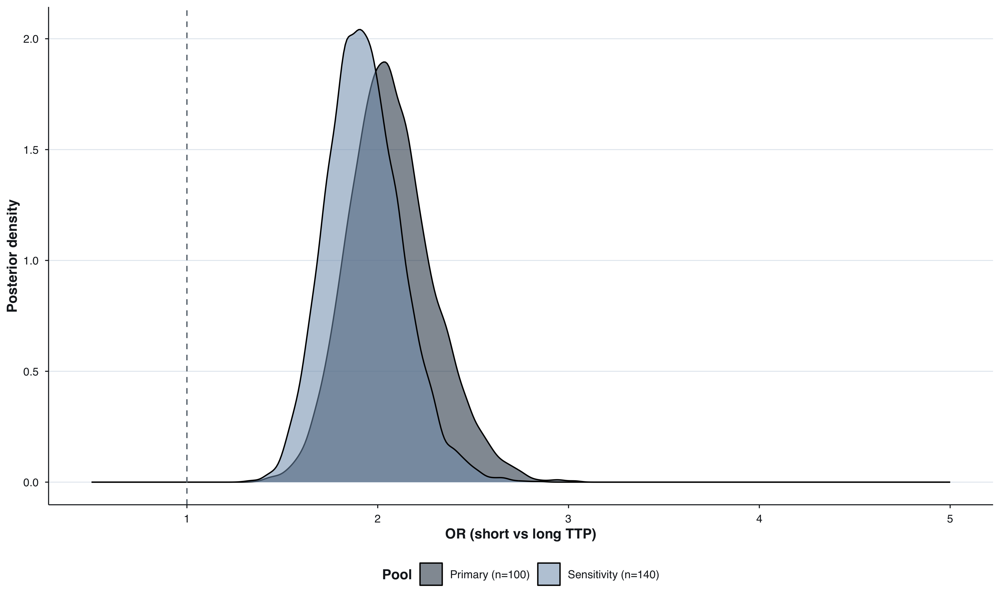

In [ ]:
#| label: fig-sens-inc
#| fig-cap: "Posterior densities of pooled OR — primary pool vs sensitivity pool (with inclusive-only studies added)."
sens_df <- bind_rows(
  tibble(OR = base_post$OR_draws, Pool = sprintf("Primary (n=%d)", attr(es_all, "n_studies"))),
  tibble(OR = inc_post$OR_draws,  Pool = sprintf("Sensitivity (n=%d)", attr(es_all_inc, "n_studies")))
)
ggplot(sens_df, aes(x = OR, fill = Pool)) +
  geom_density(alpha = 0.55) +
  geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
  scale_x_continuous(limits = c(0.5, 5)) +
  scale_fill_jama() +
  labs(x = "OR (short vs long TTP)", y = "Posterior density") +
  theme_jama() + theme(legend.position = "bottom")

## Data source (es_source)

Do pooled ORs differ depending on how the effect size was derived — from a 2×2 table vs a back-calculated reported estimate?

In [ ]:
#| label: tbl-es-source-counts
#| tbl-cap: "Effect sizes in the primary pool by derivation source."
es_mort |>
  count(es_source) |>
  mutate(
    es_source = recode(es_source,
      two_by_two           = "2×2 table",
      reported_adjusted    = "Reported (adjusted)",
      reported_unadjusted  = "Reported (unadjusted)"
    ),
    pct = sprintf("%.1f%%", 100 * n / sum(n))
  ) |>
  rename(`ES source` = es_source, N = n, `%` = pct) |>
  gt()

In [ ]:
#| label: tbl-es-source-pooled
#| tbl-cap: "Pooled OR by effect-size source. The 2×2 and reported-only estimates come from separate Bayesian RE models; contrasts come from the joint meta-regression (two_by_two as reference)."
if (!is.null(fits$fit_2x2) && !is.null(fits$fit_reported) &&
    !is.null(fits$fit_es_source)) {

  post_2x2 <- pooled_summary(fits$fit_2x2)
  post_rep  <- pooled_summary(fits$fit_reported)

  # Meta-regression draws for each source level
  d_src <- as_draws_df(fits$fit_es_source)
  b_adj   <- d_src[[grep("reported_adjusted",    names(d_src), value = TRUE)[1]]]
  b_unadj <- d_src[[grep("reported_unadjusted",  names(d_src), value = TRUE)[1]]]

  contr <- tibble(
    Source      = c("Reported (adjusted) vs 2×2",
                    "Reported (unadjusted) vs 2×2"),
    `Δ log-OR`  = sprintf("%.3f", c(median(b_adj), median(b_unadj))),
    `95% CrI`   = sprintf("[%.3f, %.3f]",
                           c(quantile(b_adj,   0.025), quantile(b_unadj,   0.025)),
                           c(quantile(b_adj,   0.975), quantile(b_unadj,   0.975))),
    `P(Δ ≠ 0)`  = sprintf("%.1f%%",
                           c(mean(b_adj   > 0), mean(b_unadj > 0)) * 100)
  )

  bind_rows(
    tibble(Source = "2×2 table",
           `Median OR` = sprintf("%.2f", post_2x2$median_OR),
           `95% CrI`   = sprintf("[%.2f, %.2f]", post_2x2$ci_OR[1], post_2x2$ci_OR[2]),
           `N` = sprintf("%d", nrow(filter(es_mort, es_source == "two_by_two")))),
    tibble(Source = "Reported (any)",
           `Median OR` = sprintf("%.2f", post_rep$median_OR),
           `95% CrI`   = sprintf("[%.2f, %.2f]", post_rep$ci_OR[1], post_rep$ci_OR[2]),
           `N` = sprintf("%d", nrow(filter(es_mort, grepl("reported", es_source)))))
  ) |> gt() |>
    tab_style(style = cell_text(weight = "bold"),
              locations = cells_column_labels())
}

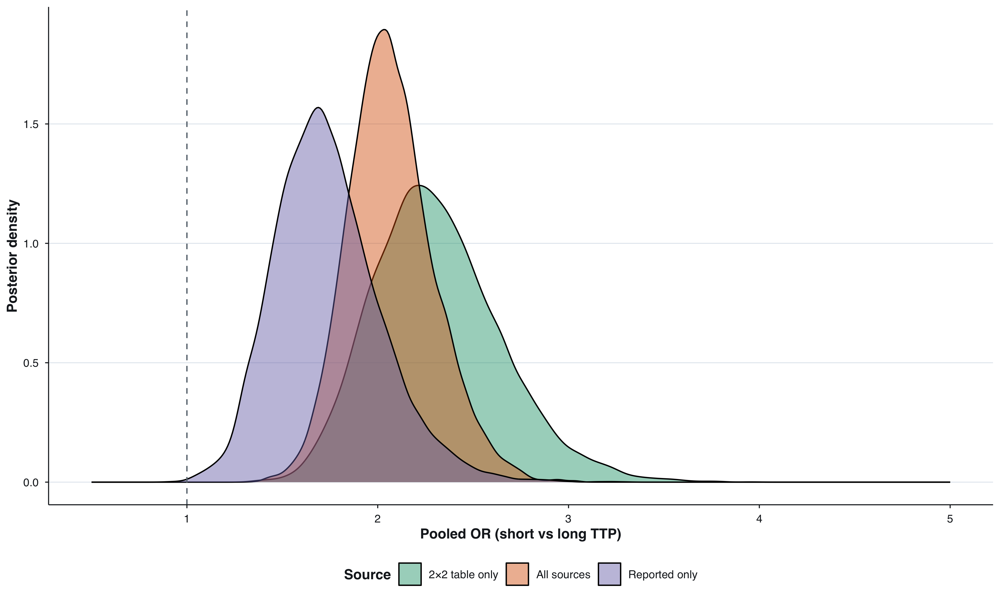

In [ ]:
#| label: fig-es-source-density
#| fig-cap: "Posterior densities of pooled OR by effect-size source. Substantial overlap indicates the signal is not driven by one derivation method."
if (!is.null(fits$fit_2x2) && !is.null(fits$fit_reported)) {
  post_2x2 <- pooled_summary(fits$fit_2x2)
  post_rep  <- pooled_summary(fits$fit_reported)

  bind_rows(
    tibble(OR = base_post$OR_draws,   Source = "All sources"),
    tibble(OR = post_2x2$OR_draws,    Source = "2×2 table only"),
    tibble(OR = post_rep$OR_draws,    Source = "Reported only")
  ) |>
    ggplot(aes(x = OR, fill = Source)) +
    geom_density(alpha = 0.45) +
    geom_vline(xintercept = 1, linetype = "dashed", color = jama_ref_line) +
    scale_x_continuous(limits = c(0.5, 5)) +
    scale_fill_brewer(palette = "Dark2") +
    labs(x = "Pooled OR (short vs long TTP)", y = "Posterior density") +
    theme_jama() +
    theme(legend.position = "bottom")
}

In [ ]:
#| label: tbl-es-source-contrasts
#| tbl-cap: "Meta-regression contrasts vs the 2×2-derived reference. A positive Δ log-OR indicates the reported-estimate sources show a larger short-TTP harm signal than the 2×2 pool."
if (!is.null(fits$fit_es_source)) {
  d_src   <- as_draws_df(fits$fit_es_source)
  b_adj   <- d_src[[grep("reported_adjusted",   names(d_src), value = TRUE)[1]]]
  b_unadj <- d_src[[grep("reported_unadjusted", names(d_src), value = TRUE)[1]]]

  tibble(
    Contrast    = c("Reported (adjusted) vs 2×2",
                    "Reported (unadjusted) vs 2×2"),
    `Δ log-OR`  = sprintf("%+.3f", c(median(b_adj), median(b_unadj))),
    `95% CrI`   = sprintf("[%+.3f, %+.3f]",
                           c(quantile(b_adj,   0.025), quantile(b_unadj,   0.025)),
                           c(quantile(b_adj,   0.975), quantile(b_unadj,   0.975))),
    `P(Δ > 0)`  = sprintf("%.1f%%",
                           c(mean(b_adj > 0), mean(b_unadj > 0)) * 100)
  ) |> gt()
}

## Convergence — sensitivity pool

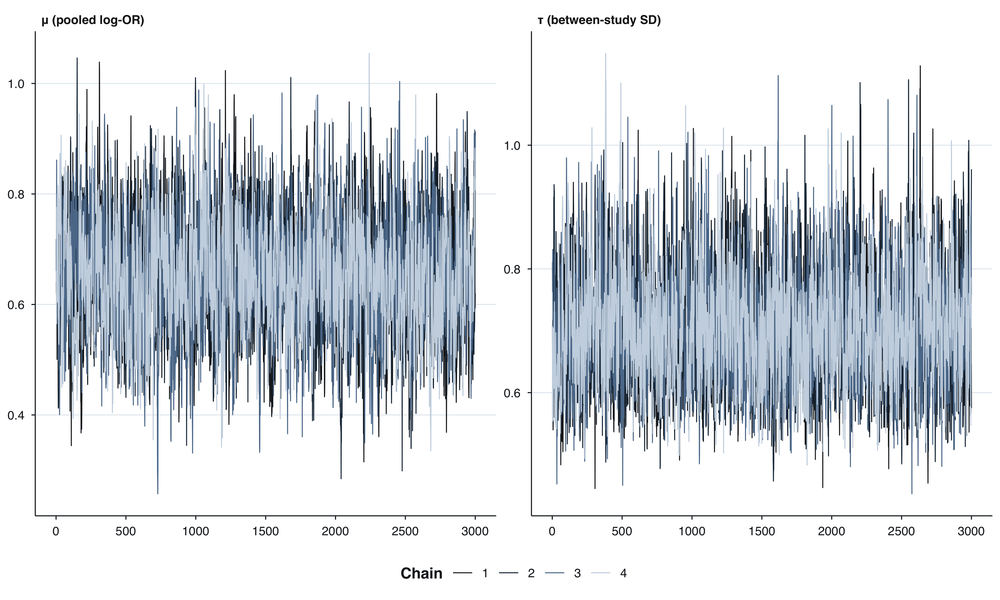

In [ ]:
#| label: fig-trace-sens
#| fig-cap: "Trace plots for key parameters of the sensitivity (n=140) model."
#| fig-height: 6
bayesplot::mcmc_trace(
  fits_inc$fit_base,
  pars = c("b_Intercept", "sd_study_id__Intercept"),
  facet_args = list(labeller = as_labeller(c(
    b_Intercept              = "μ (pooled log-OR)",
    sd_study_id__Intercept   = "τ (between-study SD)"
  )))
) +
  theme_jama(base_size = 11)

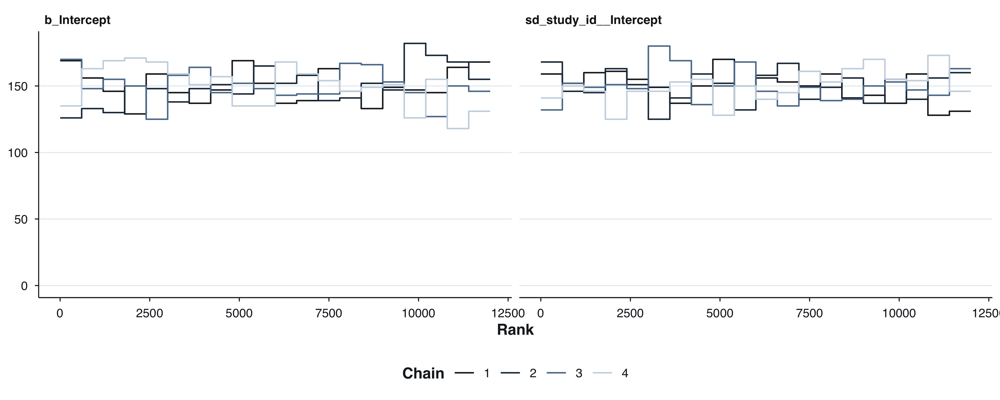

In [ ]:
#| label: fig-rank-sens
#| fig-cap: "Rank histograms for key parameters of the sensitivity (n=140) model."
#| fig-height: 4
bayesplot::mcmc_rank_overlay(
  fits_inc$fit_base,
  pars = c("b_Intercept", "sd_study_id__Intercept")
) +
  theme_jama(base_size = 11)

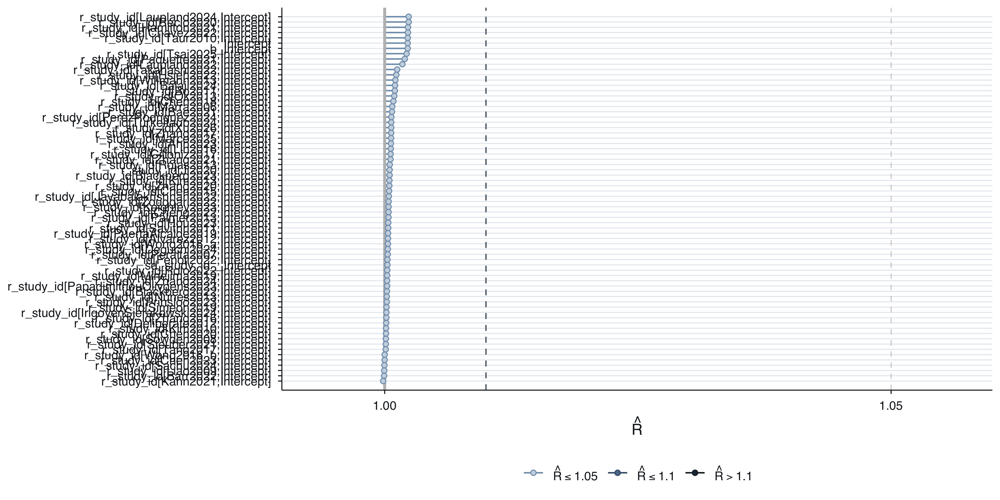

In [ ]:
#| label: fig-rhat-sens
#| fig-cap: "R̂ dot plot for all parameters of the sensitivity (n=140) model. All values should fall below 1.01 (dashed line)."
#| fig-height: 5
rhat_vals_sens <- posterior::summarise_draws(fits_inc$fit_base, rhat = posterior::rhat) |>
  filter(!grepl("^lp__|^lprior", variable)) |>
  (\(d) setNames(d$rhat, d$variable))()

bayesplot::mcmc_rhat(rhat_vals_sens) +
  geom_vline(xintercept = 1.01, linetype = "dashed", color = jama_ref_line) +
  theme_jama(base_size = 11)

## Other moderators

In [ ]:
#| label: tbl-mods
#| tbl-cap: "All moderator and sensitivity analyses (primary pool). Δ log-OR is the change in pooled log-OR per unit of the moderator; negative values shrink the short-TTP harm signal."
mod_row <- function(fit, name, scale = 1, p_dir = "<") {
  if (is.null(fit)) return(tibble(Moderator = name, `Δ log-OR` = "—", `95% CrI` = "—", `P(direction)` = "—"))
  d <- as_draws_df(fit)
  b <- d[[grep("^b_(?!Intercept)", names(d), perl = TRUE)[1]]]
  if (is.null(b)) return(tibble(Moderator = name, `Δ log-OR` = "—", `95% CrI` = "—", `P(direction)` = "—"))
  pdir <- if (p_dir == "<") mean(b < 0) else mean(b > 0)
  tibble(
    Moderator = name,
    `Δ log-OR` = sprintf("%.3f", median(b) * scale),
    `95% CrI`  = sprintf("[%.3f, %.3f]",
                         quantile(b, 0.025) * scale,
                         quantile(b, 0.975) * scale),
    `P(direction)` = sprintf("%.1f%%", pdir * 100)
  )
}

bind_rows(
  mod_row(fits$fit_cutpoint,   "TTP cutpoint (per 10 h)", scale = 10),
  mod_row(fits$fit_metareg,    "Pathogen: Gram+ vs Gram−"),
  mod_row(fits$fit_adjustment, "Adjustment: adjusted vs unadjusted", p_dir = ">"),
  mod_row(fits$fit_year,       "Publication year (per 5 yr)",       scale = 5)
) |> gt()

# Data quality / risk of bias

See the **Risk of bias** page for the traffic-light QUIPS plot. Quick summary:

In [ ]:
rob_summary <- attr(es_all, "tbl_study") |>
  count(rob_overall) |>
  mutate(`%` = sprintf("%.1f%%", 100 * n / sum(n))) |>
  arrange(factor(rob_overall, levels = c("low", "moderate", "high", "critical")))
rob_summary |> gt()

# Reproducibility

All analyses are reproducible from this Quarto project:

1.  `git clone` the repo
2.  Open `ttp-meta-v4.Rproj` in RStudio (or `cd` in)
3.  `renv::restore()` (or install packages listed in `R/01_prepare_data.R` + `R/02_fit_models.R`)
4.  `quarto render` — first build will compile Stan models (~10–20 min); subsequent builds use the cached `_brms_cache/`

In [ ]:
#| code-fold: true
sessionInfo()

R version 4.5.1 (2025-06-13)
Platform: aarch64-apple-darwin20
Running under: macOS 27.2

Matrix products: default
BLAS:   /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.0.dylib 
LAPACK: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.12.1

locale:
[1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Europe/Rome
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] lme4_2.0-6          readxl_1.5.0.1      gt_1.3.0           
 [4] knitr_1.52          patchwork_1.3.2     ggdist_3.3.3       
 [7] bayesplot_1.15.0    posterior_1.7.0     metafor_5.2-1      
[10] numDeriv_2016.8-1.1 metadat_1.6-0       Matrix_1.7-6       
[13] brms_2.23.0         Rcpp_1.1.2          lubridate_1.9.5    
[16] forcats_1.0.1       stringr_1.6.0       dplyr_1.2.1        
[19] purrr_1.2.2         readr_2.2.0         tidyr_1.3.2       